In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

In [5]:
F = 100
x_f = 0.5
D = 45
alpha = 2
x_d = 0.95
q = 0.5
x = np.linspace(0, 1, 10)

In [6]:
#Overall Material Balance 
def OMB(F, D):
    B = F - D
    return B
#Component Balance    
def CMB(F, D, B, x_d, x_f):
    x_b = (F*x_f - D*x_d)/B
    return x_b

In [7]:
def qline(x, x_f, q):
    y = []
    for x_i in x:
        y_i = q*x_i/(q-1) - x_f/(q-1)
        y.append(y_i)
    return y 

In [8]:
def VLE(x, alpha):
    y_vle = []
    for x_i in x:
        y_i = (alpha*x_i)/(1 + (alpha - 1)*x_i)
        y_vle.append(y_i)
    return y_vle

In [9]:
#Intersection of q line and VLE to get (x_q,y_q) 
def f(x, x_f, q):
    return q*x/(q-1) - x_f/(q-1)
def g(x, alpha):
    return alpha*x/(1 + (alpha - 1)*x)
def get_xq(x, x_f, q, alpha):
    return f(x, x_f, q) - g(x, alpha)
alpha = 2
x_f = 0.5
q = 0.5
initial_guess = 0.4
sol = fsolve(get_xq, x0 = initial_guess, args = (x_f, q, alpha))


In [10]:
B = OMB(F, D)
x_b = CMB(F, D, B, x_d, x_f)
y_qline = qline(x, x_f, q)
y_vle = VLE(x, alpha)
x_q = sol[0] #value of x_q
y_q = q*x_q/(q-1) - x_f/(q-1)
y_q #value of x_q

0.5857864376269049

In [11]:
# To calculate Rmin
def Rect(x, R, x_d):
    y_rect = []
    for x_i in x:
        y_i = x_i*R/(R + 1) + x_d/(R + 1)
        y_rect.append(y_i)
    return y_rect
def get_Rmin(Rmin, x_q, y_q, x_d):        
    return y_q - Rmin*x_q/(Rmin + 1) - x_d/(Rmin + 1)
x_q = 0.414
y_q = 0.586
x_d = 0.95
initial_guess = 1
sol1 = fsolve(get_Rmin, x0 = initial_guess, args =(x_q, y_q, x_d))
Rmin = sol1[0] # Value of Rmin
Ract = 1.5 * Rmin
Ract

3.1744186046511587

In [12]:
#To get (x_r, y_r)
def h(x, Ract, x_d):   
    return Ract*x/(Ract + 1) + x_d/(Ract + 1)
def get_xr(x, Ract, x_d, x_f, q):
    return h(x, Ract, x_d) - f(x, x_f, q)
initial_guess = 0.3

sol3 = fsolve(get_xr, x0 = initial_guess, args = (Ract, x_d, x_f, q))
x_r = sol3[0]
y_r = Ract*x_r/(Ract + 1) + x_d/(Ract + 1)
y_r

0.5612341772151899

In [13]:
#To get stripping line
point1 = (x_b, x_b)
point2 = (x_r, y_r)
x_n = [point1[0], point2[0]]
y_n = [point1[1], point2[1]]

m, c = np.polyfit(x_n, y_n, 1)

print(f"Slope (m): {m:.2f}")
print(f"Intercept (c): {c:.2f}")
print(f"Equation: y = {m:.2f}x + {c:.2f}")

def Strip(x, m, c):
     y_strip = []
     for x_i in x:
        y_i = m*x_i + c
        y_strip.append(y_i)
     return y_strip

Slope (m): 1.40
Intercept (c): -0.05
Equation: y = 1.40x + -0.05


In [37]:
def Stages(x_d, x_r, x_b, Ract, alpha):
    x1 = x_d
    y1 = x_d
    Nr = 0
    Ns = 0
    stgs = []
    while x1 >= x_f:
        y2 = y1
        x2 = y2/(alpha - (alpha - 1)*y2)
        
        x3 = x2
        y3 = (Ract*x3 + x_d)/(Ract + 1)
        
        p1 = (x1, y1)
        p2 = (x2, y2)
        p3 = (x3, y3)
        stgs.append([p1, p2, p3])
        
        x1 = x3
        y1 = y3
        Nr = Nr + 1
        
    while x1 < x_f and x1 >= x_b:
        y2 = y1
        x2 = y2/(alpha - (alpha - 1)*y2)
        
        x3 = x2
        y3 = 1.4*x3 - 0.05
        
        p1 = (x1, y1)
        p2 = (x2, y2)
        p3 = (x3, y3)
        stgs.append([p1, p2, p3])
        
        x1 = x3
        y1 = y3
        Ns = Ns + 1
    N = Nr + Ns
    return stgs, N
stgs, N = Stages(x_d, x_r, x_b, Ract, alpha) 


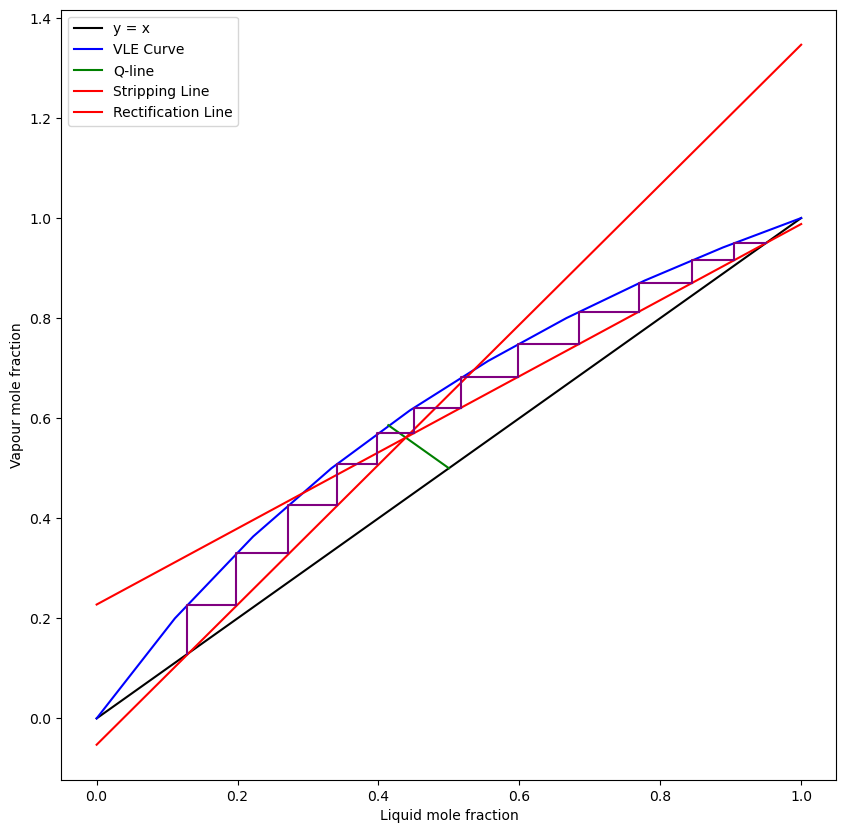

Number of stages:  12


In [38]:
fig, ax = plt.subplots(figsize=(10,10))

x_diag = np.linspace(0,1,10)
y_diag = x_diag
y_rect = Rect(x, Ract, x_d)
y_strip = Strip(x, m, c)
ax.plot(x_diag, y_diag, color = 'black',label = 'y = x')
ax.plot(x, y_vle, color = 'blue', label = 'VLE Curve')
ax.plot([x_q, x_f], [y_q, x_f], color = 'green', label = 'Q-line')
ax.plot(x, y_strip, color = 'red', label = 'Stripping Line')
ax.plot(x, y_rect, color = 'red', label = 'Rectification Line')
for stage in stgs:
    xcoord = (stage[0][0], stage[1][0], stage[2][0])
    ycoord = (stage[0][1], stage[1][1], stage[2][1])
    ax.plot(xcoord, ycoord, color = 'purple', linestyle = '-')
plt.xlabel('Liquid mole fraction')
plt.ylabel('Vapour mole fraction')
plt.legend()
plt.show()
print("Number of stages: ", N)